# Розпізнавання звуків навколишнього середовища: двигун / сирена / дощ
**Модель:** YAMNet (Google, TensorFlow Hub `google/yamnet/1`, Apache 2.0) — CNN MobileNet v1, навчена на AudioSet (521 клас).
**Дані:** ESC-50 (відкритий набір, CC BY-NC 3.0) — класи `engine`, `siren`, `rain`, по 15 записів на навчання і 24 нових на перевірку.
**Адаптація (transfer learning):** ваги YAMNet заморожені; її вихід-ембеддинг (1024 ознаки на кадр 0,96 с) подається в новий класифікатор Dense(256) → Dense(3).

**Google Colab:** розкоментуйте та виконайте першу комірку .

In [1]:
# !git clone --depth 1 https://github.com/Oigen5102/MIAZ_2026_work
# %cd MIAZ_2026_work/Theme_4/PR_4.13
# !pip -q install -r requirements.txt

In [2]:
import sys, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, 'src')
import json, pandas as pd
from IPython.display import Image, Audio, display
from common import Yamnet, load_audio
yam = Yamnet('auto')   # 'hub' — завантажити оригінал з TF Hub; 'tflite' — локальна копія тієї ж моделі
scores, emb = yam(load_audio('demo/02_siren.wav'))
print('backend:', yam.backend, '| кадрів:', emb.shape[0], '| розмір ембеддинга:', emb.shape[1], '| класів AudioSet:', scores.shape[1])

I0000 00:00:1792586406.607441   30622 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792586406.608269   30622 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792586408.158933   30622 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792586408.159410   30622 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


backend: tflite | кадрів: 10 | розмір ембеддинга: 1024 | класів AudioSet: 521


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## 1. Навчання нового класифікатора на ознаках YAMNet

In [3]:
!python src/train.py 2>/dev/null

YAMNet backend: tflite


Навчальних записів: 45, кадрів-ознак: (438, 1024)


train acc (кадри): 1.000



Тест (72 нових записів): точність класифікатора = 0.986, YAMNet zero-shot = 0.931
              precision    recall  f1-score   support

      engine      1.000     0.958     0.979        24
       siren      1.000     1.000     1.000        24
        rain      0.960     1.000     0.980        24

    accuracy                          0.986        72
   macro avg      0.987     0.986     0.986        72
weighted avg      0.987     0.986     0.986        72

Матриця помилок (рядки — істина):
 [[23  0  1]
 [ 0 24  0]
 [ 0  0 24]]


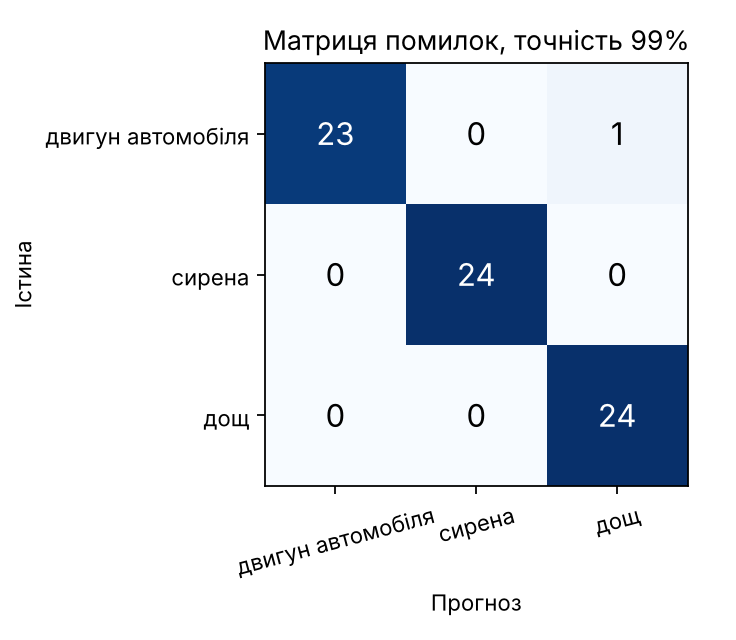

In [4]:
display(Image('results/confusion_matrix.png', width=380))

## 2. Демонстрація на нових записах (не брали участі в навчанні)

In [5]:
from predict import SoundClassifier
clf = SoundClassifier(threshold=0.7)
import glob
rows = []
for f in sorted(glob.glob('demo/*.wav')):
    r = clf.predict(f)
    rows.append({'файл': f.split('/')[-1], 'прогноз': r['class_ua'], 'впевненість': f"{r['confidence']:.0%}",
                 'низька впевненість': '⚠️' if r['uncertain'] else '', 'YAMNet top-1 (AudioSet)': r['yamnet_top1']})
pd.DataFrame(rows)

E0000 00:00:1792586426.047845   30622 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


,файл,прогноз,впевненість,низька впевненість,YAMNet top-1 (AudioSet)
0,01_engine.wav,двигун автомобіля,100%,,Engine
1,02_siren.wav,сирена,100%,,Siren
2,03_rain.wav,дощ,100%,,Vehicle
3,04_engine_error.wav,дощ,87%,,Chainsaw
4,05_rain_uncertain.wav,дощ,52%,⚠️,Vehicle
5,06_helicopter_ood.wav,двигун автомобіля,100%,,Vehicle
6,07_thunderstorm_ood.wav,дощ,59%,⚠️,Thunderstorm


In [6]:
for f in ['demo/01_engine.wav', 'demo/04_engine_error.wav', 'demo/06_helicopter_ood.wav']:
    print(f); display(Audio(f))

demo/01_engine.wav


demo/04_engine_error.wav


demo/06_helicopter_ood.wav


## 3. Помилки на тестовому наборі

In [7]:
m = json.load(open('results/metrics.json'))
print(f"Точність: класифікатор {m['accuracy_head']:.1%} | YAMNet без донавчання {m['accuracy_zero_shot']:.1%} | тестових записів: {m['n_test_clips']}")
pd.DataFrame(m['errors'])

Точність: класифікатор 98.6% | YAMNet без донавчання 93.1% | тестових записів: 72


,file,true,pred,conf,p_engine,p_siren,p_rain,zero_shot,yamnet_top1
0,4-171652-A-44.wav,engine,rain,0.869,0.122,0.009,0.869,engine,Chainsaw


**Висновки.** `04_engine_error` — двигун з високим «пиляючим» тембром (YAMNet бачить у ньому *Chainsaw*): широкосмуговий шум схожий на дощ, а таких двигунів у 15 навчальних записах не було.
`06_helicopter_ood` — гелікоптера немає серед класів, тому модель упевнено (≈100%) називає його двигуном: класифікатор із закритим набором класів не вміє сказати «не знаю». Поріг впевненості відсікає лише частину сторонніх звуків (`07_thunderstorm_ood`).